# Understanding differentiable quantum circuits for differential equations

**A guided, runnable companion to _Solving nonlinear differential equations with differentiable quantum circuits_**  
Oleksandr Kyriienko, Annie E. Paine, and Vincent E. Elfving, arXiv:2011.10395v2 (2021).

The paper turns **solving a differential equation** into **training a quantum circuit**. A circuit produces a trial function. Other, slightly modified circuits produce its derivatives. A classical optimizer changes the circuit until the function and derivatives satisfy the equation and its initial conditions.

This notebook explains the method from scratch and implements a small, real statevector simulation using NumPy. No quantum hardware, cloud account, quantum SDK, or data download is needed. Saved outputs let you read it without running anything.

**Scope:** this is a teaching implementation, not a reproduction of every experiment or a demonstration of quantum speedup. We train a simple nonlinear example, then the paper's actual nonlinear equation (32) using a smaller circuit. We explain the coupled-system and nozzle-flow experiments separately.

**Background:** basic Python, vectors/matrices, and the idea of a derivative. Quantum notation is explained as it appears. Allow about 45–75 minutes to read and experiment.

## Route through the notebook

1. What problem is the paper solving?
2. How can a quantum circuit represent a function?
3. Why use Chebyshev feature maps?
4. How do shifted circuits give exact derivatives?
5. How do initial conditions and training work?
6. Train a nonlinear ODE solver, then try equation (32).
7. Understand the other paper experiments, costs, and limitations.

References such as **Eq. (15)** and **Fig. 7** refer to the supplied v2 PDF. Numbered headings below refer to this notebook.

## 0. Setup

Run cells from top to bottom in a Python 3.10+ Jupyter kernel. In VS Code, select a Python environment containing the packages below. If needed, uncomment and run the installation line once, then restart the kernel. It is deliberately inactive so **Run All does not install or download anything**.

Only NumPy, SciPy, and Matplotlib are needed by the examples. All randomness has a fixed seed. A full run took about one minute in the validation environment; allow a few minutes on a slower computer. Training speed and the last few digits can vary across machines and library versions.

In [1]:
!pip install numpy scipy matplotlib
import sys
import time
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from scipy.integrate import solve_ivp
from scipy.linalg import expm
from numpy.polynomial import chebyshev as cheb

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"figure.figsize": (10, 3.6), "axes.grid": True,
                     "grid.alpha": 0.2, "font.size": 11})
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | "
      f"SciPy {scipy.__version__} | Matplotlib {matplotlib.__version__}")

Python 3.12.12 | NumPy 2.5.4 | SciPy 1.18.1 | Matplotlib 3.11.2


## 1. The problem: find a function, not just a number

Suppose we know
$$
u'(x)+u(x)^2=0,\qquad u(0)=1.
$$
This equation says: “the rate of change equals minus the square of the current value.” The unknown is the **whole function** $u$. It is nonlinear because of $u^2$.

For this introductory example, separation of variables gives $u(x)=1/(1+x)$. We will hide that formula from the training code and use it only to check the answer. **This introductory equation is chosen for this notebook; it is not one of the paper's numbered examples.**

Let $f_\theta(x)$ be a trial function with adjustable parameters $\theta$. At any input, its **residual** is
$$
r_\theta(x)=f'_\theta(x)+f_\theta(x)^2.
$$
The residual is zero for a solution. Choose sample inputs $x_i$ (called **collocation points**) and minimize
$$
\mathcal L_{\mathrm{DE}}=\frac1M\sum_{i=1}^M r_\theta(x_i)^2.
$$
The optimizer sees the equation and initial value, **not a table of correct solution values**. Boundary conditions matter: the wrong function $f=0$ also has zero residual, but violates $u(0)=1$.

The paper uses this same idea for a general equation $F(x,f,f',f'',\ldots)=0$ and for several coupled functions (Sec. II, Eqs. (3)–(4), Sec. III D).

| Part of the solver | Job |
|---|---|
| Feature map $U_\varphi(x)$ | Put the input $x$ into rotation angles |
| Trainable circuit $U_\theta$ | Adjust the shape of the trial function |
| Observable $C$ | Convert a quantum state into a scalar output |
| Derivative circuits | Evaluate $f'$ and, if needed, higher derivatives |
| Classical loss and optimizer | Combine outputs into residuals and update parameters |

This resembles a physics-informed neural network: the function approximator is a quantum circuit. Multiplications such as $f^2$ happen in **classical post-processing**; quantum evolution does not need to become nonlinear.

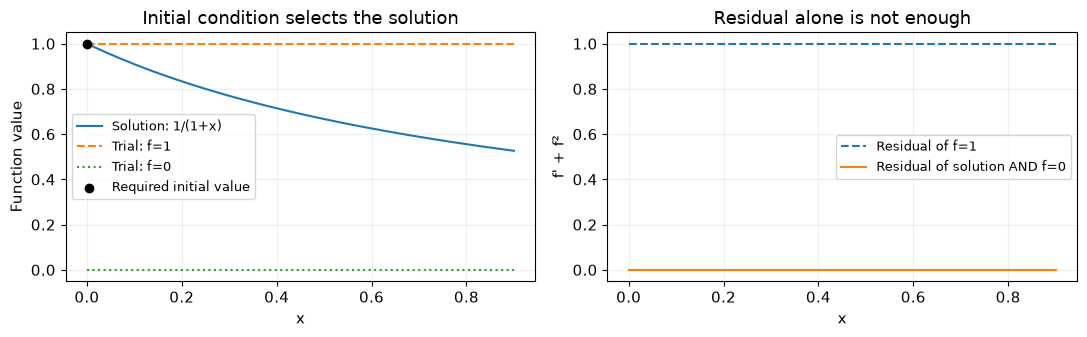

In [2]:
x = np.linspace(0, 0.9, 200)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(x, 1/(1+x), label="Solution: 1/(1+x)")
ax[0].plot(x, np.ones_like(x), "--", label="Trial: f=1")
ax[0].plot(x, np.zeros_like(x), ":", label="Trial: f=0")
ax[0].scatter([0], [1], c="black", zorder=5, label="Required initial value")
ax[0].set(xlabel="x", ylabel="Function value", title="Initial condition selects the solution")
ax[0].legend(fontsize=9)
ax[1].plot(x, np.ones_like(x), "--", label="Residual of f=1")
ax[1].plot(x, np.zeros_like(x), label="Residual of solution AND f=0")
ax[1].set(xlabel="x", ylabel="f' + f²", title="Residual alone is not enough")
ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

## 2. A quantum circuit is a parameterized function

A qubit state is a length-two complex vector $|\psi\rangle=a|0\rangle+b|1\rangle$, with $|a|^2+|b|^2=1$. A **gate** is a matrix preserving this normalization. For $N$ qubits, the statevector has $2^N$ entries. We simulate those entries explicitly, which is why this notebook uses small circuits.

We need just three gates:

$$
R_y(\alpha)=\begin{pmatrix}\cos(\alpha/2)&-\sin(\alpha/2)\\
\sin(\alpha/2)&\cos(\alpha/2)\end{pmatrix},\qquad
R_z(\alpha)=\mathrm{diag}(e^{-i\alpha/2},e^{i\alpha/2}).
$$

A **CNOT** flips a target bit when its control bit is 1. It can entangle qubits. Our trainable layers use $R_y$, $R_z$, and a chain of CNOTs; the paper's hardware-efficient circuit uses $R_z$–$R_x$–$R_z$ layers and CNOTs (Sec. III B, Fig. 5).

The circuit constructs
$$
|\psi_\theta(x)\rangle=U_\theta U_\varphi(x)|0\cdots0\rangle,
\qquad q_\theta(x)=\langle\psi_\theta(x)|C|\psi_\theta(x)\rangle.
$$
Read the rightmost operation first. The brackets mean a matrix expectation value, $\psi^\dagger C\psi$ (paper Eq. (1)). We reserve $q$ for the raw circuit output and $f$ for the output after boundary handling.

For $C=Z=\mathrm{diag}(1,-1)$, the expectation is $P(0)-P(1)$, between $-1$ and $1$. A single measurement gives only $+1$ or $-1$; many repetitions estimate the expectation. In the simulation we compute it exactly, up to floating-point error.

**One-qubit example:** $R_y(\alpha)|0\rangle$ has $\langle Z\rangle=\cos\alpha$. Setting $\alpha=x+\theta$ already gives a tunable function.

In [3]:
def ry(angle):
    c, s = np.cos(angle/2), np.sin(angle/2)
    return np.array([[c, -s], [s, c]], dtype=complex)

def rz(angle):
    return np.diag(np.exp(np.array([-0.5j, 0.5j])*angle))

Z = np.diag([1.0, -1.0])
ket0 = np.array([1.0, 0.0], dtype=complex)
alpha = 0.73
psi = ry(alpha) @ ket0
expectation = np.vdot(psi, Z @ psi).real
print("Probabilities:", abs(psi)**2)
print("<Z> from the state:", expectation)
print("cos(alpha):       ", np.cos(alpha))
assert np.allclose(expectation, np.cos(alpha))
assert np.allclose(ry(alpha).conj().T @ ry(alpha), np.eye(2))

Probabilities: [0.872587 0.127413]
<Z> from the state: 0.7451744023448705
cos(alpha):        0.7451744023448704


## 3. Why Chebyshev feature maps?

The **feature map** decides which patterns are available before training. The paper compares (Sec. III A):

| Name | Rotation on qubit $j$ | Paper |
|---|---|---|
| Product (Prod) | $R_y(\arcsin x)$ | Eq. (6) |
| Chebyshev (Cheb) | $R_y(2\arccos x)$ | Eq. (14) |
| Chebyshev tower (ChebT) | $R_y(2j\arccos x)$, $j=1,\ldots,N$ | Eq. (15) |

The key identity is $T_n(x)=\cos(n\arccos x)$. Thus
$$
R_y(2n\arccos x)|0\rangle
=T_n(x)|0\rangle+\sin(n\arccos x)|1\rangle.
$$
The second amplitude is $\sqrt{1-x^2}\,U_{n-1}(x)$, where $U$ denotes a Chebyshev polynomial of the second kind. Products across qubits and mixing by the trainable circuit build richer functions from these ingredients.

**Amplitude is not expectation:** the $|0\rangle$ amplitude here is $T_n$, but measuring $Z$ gives $\cos(2n\arccos x)=T_{2n}(x)$. A generic trained expectation can also contain square-root-weighted terms; it is not simply an unconstrained list of polynomial coefficients.

Higher-order features help represent oscillations, but extra expressivity does not guarantee easy optimization or a quantum advantage.

**Domain:** inverse trigonometric maps require $|x|\leq1$. Their angle derivatives contain $1/\sqrt{1-x^2}$, so our solver requires $|x|<1$. For a physical interval $s\in[a,b]$, map it into an interior interval, e.g. $x=0.8[2(s-a)/(b-a)-1]$, and use $df/ds=(df/dx)\,1.6/(b-a)$. Do not forget this chain-rule factor.

**A correction when reading p. 6:** derivatives of the polynomials $T_n$ themselves do not diverge at the endpoints; $T_n'(1)=n^2$ is finite. The angle $\arccos x$ has a singular derivative, and some other circuit features can have endpoint singularities.

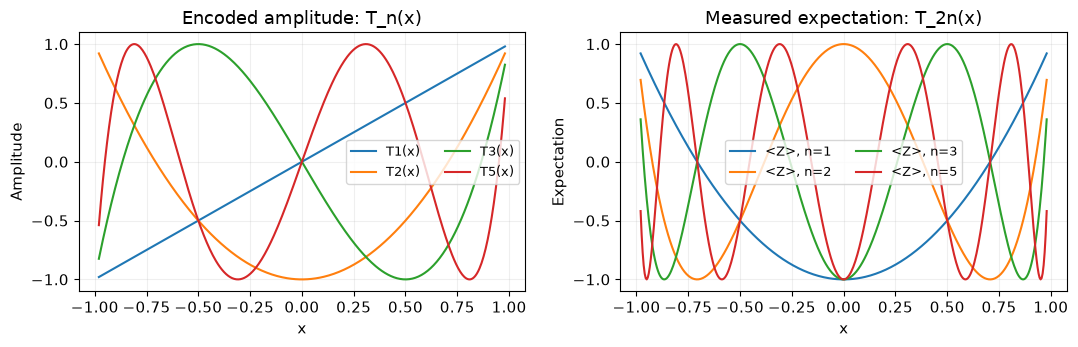

In [4]:
z = np.linspace(-0.98, 0.98, 400)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for n in [1, 2, 3, 5]:
    amplitude = np.cos(n*np.arccos(z))
    polynomial = cheb.chebval(z, [0]*n + [1])
    assert np.allclose(amplitude, polynomial)
    ax[0].plot(z, amplitude, label=f"T{n}(x)")
    ax[1].plot(z, np.cos(2*n*np.arccos(z)), label=f"<Z>, n={n}")
ax[0].set(title="Encoded amplitude: T_n(x)", xlabel="x", ylabel="Amplitude")
ax[1].set(title="Measured expectation: T_2n(x)", xlabel="x", ylabel="Expectation")
for a in ax: a.legend(ncol=2, fontsize=9)
plt.tight_layout(); plt.show()

## 4. Differentiation by shifting gate angles

For a gate $R_P(\alpha)=e^{-i\alpha P/2}$ with $P^2=I$, and with that angle appearing in **one gate**, its expectation obeys
$$
\frac{\partial q}{\partial\alpha}
=\frac{q(\alpha+\pi/2)-q(\alpha-\pi/2)}2.
$$
This is an exact identity, not a small-step approximation. If $x$ enters several angles $\varphi_j(x)$, the chain rule gives
$$
\boxed{\frac{dq}{dx}
=\sum_j\frac{\varphi'_j(x)}2\left[q_{j,+}(x)-q_{j,-}(x)\right].}
$$
Here $q_{j,\pm}$ shifts **only the $j$th encoding gate angle**, keeping the input and all other gates fixed (paper Fig. 3). For ChebT, $\varphi'_j(x)=-2j/\sqrt{1-x^2}$.

Do not shift $x$ itself by $\pi/2$, or shift every gate at once. Both would compute something different.

**Normalization note:** Eq. (9) in the supplied PDF prints a $1/4$ prefactor. With the rotation convention of Eq. (5) and ordinary shifted expectations, the one-qubit calculation above requires $1/2$. We use the identity derived here and test it below.

There are two different derivatives in training:

- $\partial f/\partial x$: used inside the differential equation.
- $\partial\mathcal L/\partial\theta_k$: tells the optimizer how to update a gate angle.

For $r=f'+f^2$, the latter uses
$$
\partial_{\theta_k}r
=\partial_{\theta_k}f'+2f\,\partial_{\theta_k}f,
\qquad
\partial_{\theta_k}\mathcal L=\frac2M\sum_i r_i\partial_{\theta_k}r_i.
$$
We shift **circuit expectations** to obtain those derivatives and then apply the classical chain rule. Applying the simple two-shift formula directly to the nonlinear squared loss is generally wrong.

In [5]:
# A minimal parameter-shift check, including the nonlinear angle map.
test_x = np.array([-0.7, -0.1, 0.3, 0.8])
n = 3
phi = 2*n*np.arccos(test_x)
phi_prime = -2*n / np.sqrt(1-test_x**2)
shift_derivative = phi_prime * (np.cos(phi+np.pi/2)-np.cos(phi-np.pi/2))/2
poly_derivative = cheb.chebval(test_x, cheb.chebder([0]*(2*n)+[1]))
print("Maximum derivative error:", np.max(abs(shift_derivative-poly_derivative)))
assert np.allclose(shift_derivative, poly_derivative, atol=1e-11)

# Higher derivatives need BOTH terms of the chain rule:
# d²q/dx² = phi'' * dq/dphi + (phi')² * d²q/dphi².
phi_second = -2*n*test_x / (1-test_x**2)**1.5
q_phi = (np.cos(phi+np.pi/2)-np.cos(phi-np.pi/2))/2
q_phiphi = (np.cos(phi+np.pi)-2*np.cos(phi)+np.cos(phi-np.pi))/4
d2_shift = phi_second*q_phi + phi_prime**2*q_phiphi
d2_exact = cheb.chebval(test_x, cheb.chebder([0]*(2*n)+[1], m=2))
assert np.allclose(d2_shift, d2_exact, atol=1e-10)
print("Second-derivative chain rule verified.")

Maximum derivative error: 4.440892098500626e-15
Second-derivative chain rule verified.


## 5. Build a small DQC simulator

The next two cells are the computational engine. Read the comments once, then focus on the experiments if the matrix bookkeeping is unfamiliar.

We use a weighted readout $q(x)=\sum_j w_j\langle Z_j\rangle$. The classical weights $w_j$ are trainable, as allowed in the paper's Eq. (18). They let the output range adapt. Setting all weights to 1 gives total magnetization, used in the paper's experiments.

The state arrays are batched over inputs for speed. A `FeatureBatch` holds the unshifted feature states and the $2N$ shifted versions needed for $dq/dx$. Caching these states is a **classical simulator optimization**; hardware would prepare and measure the corresponding circuits.

In [6]:
def apply_gate(states, gate, qubit, nqubits):
    '''Apply a 2x2 gate to one tensor axis. Qubit 0 is the leftmost bit.'''
    a = states.reshape((-1,) + (2,)*nqubits)
    a = np.moveaxis(a, qubit+1, -1)
    a = a @ gate.T
    return np.moveaxis(a, -1, qubit+1).reshape(-1, 2**nqubits)

def apply_cnot(states, control, target, nqubits):
    indices = np.arange(2**nqubits)
    active = (indices >> (nqubits-1-control)) & 1
    permutation = indices ^ (active << (nqubits-1-target))
    return states[:, permutation]

def feature_angles(x, nqubits, kind):
    x = np.atleast_1d(np.asarray(x, dtype=float))
    if np.any(abs(x) >= 1):
        raise ValueError("Use inputs strictly inside (-1, 1) for these derivative maps.")
    if kind == "Prod":
        phi = np.arcsin(x)[:, None] * np.ones((1, nqubits))
        dphi = np.ones((len(x), nqubits)) / np.sqrt(1-x[:, None]**2)
    elif kind in ("Cheb", "ChebT"):
        orders = np.ones(nqubits) if kind == "Cheb" else np.arange(1, nqubits+1)
        phi = 2*np.arccos(x)[:, None]*orders
        dphi = -2*orders / np.sqrt(1-x[:, None]**2)
    else:
        raise ValueError("kind must be Prod, Cheb, or ChebT")
    return phi, dphi

def product_states(angles):
    states = np.ones((len(angles), 1), dtype=complex)
    for j in range(angles.shape[1]):
        one_qubit = np.stack([np.cos(angles[:, j]/2), np.sin(angles[:, j]/2)], axis=1)
        states = (states[:, :, None]*one_qubit[:, None, :]).reshape(len(angles), -1)
    return states

class FeatureBatch:
    def __init__(self, x, nqubits, kind):
        self.x = np.atleast_1d(np.asarray(x, dtype=float))
        phi, self.dphi = feature_angles(self.x, nqubits, kind)
        angles = [phi]
        for j in range(nqubits):
            for sign in [1, -1]:
                shifted = phi.copy()
                shifted[:, j] += sign*np.pi/2
                angles.append(shifted)
        self.states = product_states(np.concatenate(angles, axis=0))

class DQC:
    def __init__(self, nqubits=3, depth=2, kind="ChebT"):
        self.n, self.depth, self.kind = nqubits, depth, kind
        self.ntheta = 2*nqubits*depth
        bits = np.arange(2**nqubits)
        self.zsigns = np.column_stack([
            1-2*((bits >> (nqubits-1-j)) & 1) for j in range(nqubits)])
        self.anchor = self.batch([0.0])

    def batch(self, x):
        return FeatureBatch(x, self.n, self.kind)

    def initial_parameters(self, seed=7):
        rng = np.random.default_rng(seed)
        return np.r_[rng.uniform(-0.8, 0.8, self.ntheta), np.full(self.n, 0.5)]

    def observables(self, theta, batch):
        states = batch.states.copy()
        angles = theta.reshape(self.depth, self.n, 2)
        for layer in range(self.depth):
            for j in range(self.n):
                states = apply_gate(states, ry(angles[layer, j, 0]), j, self.n)
                states = apply_gate(states, rz(angles[layer, j, 1]), j, self.n)
            for j in range(self.n-1):
                states = apply_cnot(states, j, j+1, self.n)
        # Each row gives all N expectations of Z, using exact probabilities.
        measured = (abs(states)**2) @ self.zsigns
        measured = measured.reshape(1+2*self.n, len(batch.x), self.n)
        values = measured[0]
        derivatives = np.zeros_like(values)
        for j in range(self.n):
            derivatives += batch.dphi[:, j, None] * (measured[1+2*j]-measured[2+2*j])/2
        return values, derivatives

    def raw(self, params, batch):
        values, derivatives = self.observables(params[:self.ntheta], batch)
        weights = params[self.ntheta:]
        return values @ weights, derivatives @ weights

    def predict(self, params, batch, u0=1.0):
        q, dq = self.raw(params, batch)
        q0, _ = self.raw(params, self.anchor)
        return u0 + q - q0[0], dq

    def jacobian(self, params, batch):
        '''Derivatives of floating-boundary f and f' w.r.t. every parameter.'''
        p = len(params)
        jf, jdf = np.empty((len(batch.x), p)), np.empty((len(batch.x), p))
        for k in range(self.ntheta):
            plus, minus = params.copy(), params.copy()
            plus[k] += np.pi/2
            minus[k] -= np.pi/2
            fp, dfp = self.predict(plus, batch)
            fm, dfm = self.predict(minus, batch)
            jf[:, k], jdf[:, k] = (fp-fm)/2, (dfp-dfm)/2
        values, derivatives = self.observables(params[:self.ntheta], batch)
        at_zero, _ = self.observables(params[:self.ntheta], self.anchor)
        # Classical weights enter linearly: their gradients need no shifts.
        jf[:, self.ntheta:] = values-at_zero[0]
        jdf[:, self.ntheta:] = derivatives
        return jf, jdf

## 6. Initial conditions: three choices in the paper

For the condition $f(0)=u_0$, Sec. III E describes:

| Method | Function and loss | Consequence |
|---|---|---|
| Pinned | $f=q_\theta$, add $\eta[f(0)-u_0]^2$ | Boundary and equation losses can compete |
| Floating | $f(x)=u_0+q_\theta(x)-q_\theta(0)$ | Exact initial value in noiseless arithmetic |
| Optimized | $f=c+q_\theta$, train $c$ and penalize the boundary | Extra classical freedom, still a boundary penalty |

We use **floating boundaries**, Eqs. (25)–(26). Substituting $x=0$ makes the two circuit values cancel. For the $x$ derivative, $q_\theta(0)$ is constant, so $f'=q'$. For the **parameter** derivative it is not constant:
$$
\partial_{\theta_k}f(x)=\partial_{\theta_k}q_\theta(x)-\partial_{\theta_k}q_\theta(0).
$$
The code includes this often-missed anchor term. The offset must be recomputed at every parameter update. Shifting an arbitrary solution afterwards will generally break a nonlinear equation; here the shifted function is used **inside training**.

This construction imposes one initial value per output. It does not automatically satisfy two arbitrary endpoint conditions. Independent noisy hardware estimates also do not give an exactly enforced boundary unless their reuse/handling is designed accordingly.

In [7]:
# Check the simulator before trusting training.
model = DQC(nqubits=3, depth=2, kind="ChebT")
p0 = model.initial_parameters(seed=7)
check_x = np.array([0.03, 0.27, 0.61, 0.86])
batch = model.batch(check_x)
f, df = model.predict(p0, batch)
h = 1e-6
fd = (model.predict(p0, model.batch(check_x+h))[0]
      - model.predict(p0, model.batch(check_x-h))[0])/(2*h)
print("Input derivative check, max error:", np.max(abs(df-fd)))
assert np.allclose(df, fd, atol=2e-7)
assert np.allclose(model.predict(p0, model.anchor, u0=1.7)[0], 1.7)

jf, jdf = model.jacobian(p0, batch)
parameter_errors = []
for k in range(len(p0)):
    pp, pm = p0.copy(), p0.copy()
    pp[k] += h; pm[k] -= h
    fp, dp = model.predict(pp, batch)
    fm, dm = model.predict(pm, batch)
    parameter_errors.append(max(np.max(abs(jf[:, k]-(fp-fm)/(2*h))),
                                np.max(abs(jdf[:, k]-(dp-dm)/(2*h)))))
print("Parameter and mixed derivative check, max error:", max(parameter_errors))
assert max(parameter_errors) < 2e-7
assert np.allclose(np.sum(abs(batch.states)**2, axis=1), 1)
# CNOT must map |10> to |11> and applying it twice must undo the flip.
basis10 = np.array([[0, 0, 1, 0]], dtype=complex)
assert np.allclose(apply_cnot(basis10, 0, 1, 2), [[0, 0, 0, 1]])
assert np.allclose(apply_cnot(apply_cnot(basis10, 0, 1, 2), 0, 1, 2), basis10)
print("Gate, normalization, boundary, and derivative checks passed.")
print("Finite differences above are independent checks only; training uses parameter shifts.")

Input derivative check, max error: 1.6819301507098317e-10
Parameter and mixed derivative check, max error: 3.296582007372706e-09
Gate, normalization, boundary, and derivative checks passed.
Finite differences above are independent checks only; training uses parameter shifts.


## 7. The hybrid training loop

For a scalar ODE written $u'=g(x,u)$, our residual is $r=f'-g(x,f)$. Its parameter Jacobian is
$$
J_r=J_{f'}-\frac{\partial g}{\partial u}J_f.
$$
We provide this analytic Jacobian to SciPy's nonlinear least-squares optimizer. Minimizing $\frac12\sum r_i^2/M$ has the same minimizers as the paper's mean squared residual loss. We report the latter.

The paper uses Adam. **Using least squares here is an explicit teaching simplification:** it converges efficiently for small, noiseless problems, while preserving the DQC function, shifted derivatives, residual objective, and floating boundary.

```text
choose circuit and initial parameters
repeat:
    evaluate circuit and shifted circuits at training inputs
    construct f and f' (including the initial condition)
    calculate residuals and their parameter derivatives
    let the classical optimizer propose new parameters
evaluate the resulting function on a denser, separate grid
```

No exact solution is accepted by `train_ode`. The reference solution is used only by a later reporting function. We keep the best residual seen during optimization; the plotted history counts residual evaluations, including trial steps, **not Adam iterations**.

In [8]:
def train_ode(model, x_train, u0, rhs, rhs_du, seed=7, max_nfev=180):
    batch = model.batch(x_train)
    initial = model.initial_parameters(seed)
    scale = np.sqrt(len(x_train))
    history = []
    best = {"loss": np.inf, "params": initial.copy()}

    def residual(params):
        f, df = model.predict(params, batch, u0)
        r = df-rhs(batch.x, f)
        loss = float(np.mean(r*r))
        history.append(loss)
        if loss < best["loss"]:
            best.update(loss=loss, params=params.copy())
        return r/scale

    def jac(params):
        f, _ = model.predict(params, batch, u0)
        jf, jdf = model.jacobian(params, batch)
        return (jdf-rhs_du(batch.x, f)[:, None]*jf)/scale

    start = time.perf_counter()
    result = least_squares(residual, initial, jac=jac, max_nfev=max_nfev,
                           ftol=1e-10, xtol=1e-10, gtol=1e-10)
    return {"params": best["params"], "initial": initial, "history": np.array(history),
            "result": result, "seconds": time.perf_counter()-start}

def report_fit(model, fit, x_train, u0, rhs, exact, title):
    # Dense validation points include points that were not used during training.
    xv = np.linspace(float(np.min(x_train)), float(np.max(x_train)), 401)
    f, df = model.predict(fit["params"], model.batch(xv), u0)
    before, _ = model.predict(fit["initial"], model.batch(xv), u0)
    truth = exact(xv)
    residual = df-rhs(xv, f)
    ftrain, dftrain = model.predict(fit["params"], model.batch(x_train), u0)
    metrics = {
        "training residual MSE": float(np.mean((dftrain-rhs(x_train, ftrain))**2)),
        "dense-grid residual MSE": float(np.mean(residual**2)),
        "dense-grid solution RMSE": float(np.sqrt(np.mean((f-truth)**2))),
        "dense-grid maximum solution error": float(np.max(abs(f-truth))),
        "initial-condition error": float(abs(model.predict(fit["params"], model.anchor, u0)[0][0]-u0))}
    print(title)
    print(f"Training time: {fit['seconds']:.2f} s; function evaluations: {fit['result'].nfev}")
    print("Optimizer:", fit["result"].message)
    for label, value in metrics.items(): print(f"  {label:36s} {value:.3e}")
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
    ax[0].plot(xv, truth, color="black", lw=2, label="Reference (evaluation only)")
    ax[0].plot(xv, before, ":", alpha=0.7, label="Before training")
    ax[0].plot(xv, f, "--", label="Trained DQC")
    ax[0].scatter(x_train, ftrain, s=10, alpha=0.5, label="Training inputs")
    ax[0].set(title="Function", xlabel="x", ylabel="u(x)")
    ax[0].legend(fontsize=8)
    ax[1].semilogy(np.maximum(np.minimum.accumulate(fit["history"]), 1e-18))
    ax[1].set(title="Best training loss so far", xlabel="Residual evaluation", ylabel="Mean squared residual")
    ax[2].plot(xv, residual)
    ax[2].axhline(0, color="black", lw=0.7)
    ax[2].set(title="Residual on dense grid", xlabel="x", ylabel="f' - g(x, f)")
    fig.suptitle(title, y=1.03)
    plt.tight_layout(); plt.show()
    return metrics

## 8. Experiment A: learn the nonlinear decay equation

We now train the three-qubit circuit on $u'+u^2=0$, $u(0)=1$, over $0\leq x\leq0.9$. There are 12 quantum angles and 3 classical readout weights. The circuit output changes across all inputs when one parameter changes; it is a **global function representation**, not a time-stepping algorithm.

Before running: predict the sign of $u'$ and whether the boundary error should change during training.

Teaching example: u' + u² = 0
Training time: 5.89 s; function evaluations: 180
Optimizer: The maximum number of function evaluations is exceeded.
  training residual MSE                1.125e-09
  dense-grid residual MSE              1.139e-09
  dense-grid solution RMSE             2.153e-06
  dense-grid maximum solution error    3.572e-06
  initial-condition error              0.000e+00


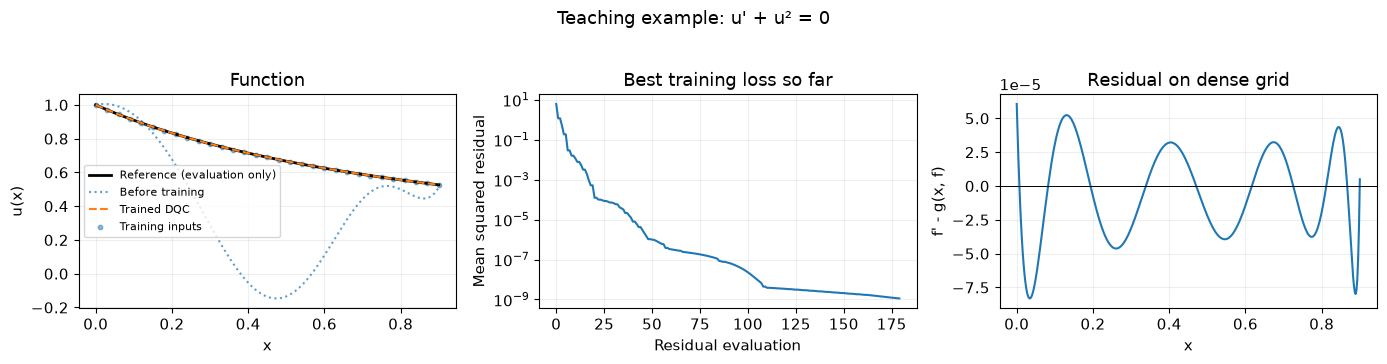

In [9]:
toy_model = DQC(nqubits=3, depth=2, kind="ChebT")
toy_x = np.linspace(0, 0.9, 31)
toy_rhs = lambda x, u: -u**2
toy_rhs_du = lambda x, u: -2*u
toy_fit = train_ode(toy_model, toy_x, 1.0, toy_rhs, toy_rhs_du,
                    seed=7, max_nfev=180)
toy_metrics = report_fit(toy_model, toy_fit, toy_x, 1.0, toy_rhs,
                        lambda x: 1/(1+x), "Teaching example: u' + u² = 0")
assert toy_metrics["initial-condition error"] < 1e-12
assert toy_metrics["dense-grid solution RMSE"] < 0.02

### What to read in the output

The left plot answers “did we find the right function?” The middle plot answers “did the optimizer reduce its objective?” The right plot asks whether the equation is satisfied **between** training points.

These are different questions. A small training loss is not a global accuracy certificate. A circuit can fit residuals at a sparse set of inputs and still behave poorly elsewhere. The dense-grid residual and solution error are separate checks, and neither certifies arbitrary extrapolation.

If the optimizer reports **“The maximum number of function evaluations is exceeded,”** the run reached its preset budget before meeting its stopping tolerances. This is not a code failure, but it is also not a convergence certificate. Judge the approximation by the reported residual and independent error metrics; the notebook keeps the best parameters evaluated.

In the paper, $L_F$ denotes the full training objective, including any boundary and regularization terms; $L_Q$ is the mean squared error against a known reference. Our solution **RMSE** is $\sqrt{L_Q}$ on the chosen validation grid. Because floating boundaries remove a boundary penalty and we add no regularization here, the training loss is just the differential residual MSE.

## 9. Experiment B: the paper's nonlinear equation (32)

The actual nonlinear benchmark in Sec. IV, Fig. 7 is
$$
u'-4u+6u^2-\sin(50x)-u\cos(25x)+\tfrac12=0,\qquad u(0)=0.75.
$$
Equivalently,
$$
g(x,u)=4u-6u^2+\sin(50x)+u\cos(25x)-\tfrac12,\quad
\partial_u g=4-12u+\cos(25x).
$$
The oscillating forcing makes this much harder than Experiment A. We use 3 qubits, 3 trainable layers, ChebT, 80 collocation points, and a limited optimization budget. This small version may miss fine oscillations. **It is a mechanism demonstration on the paper's equation, not a replication of Fig. 7.**

For comparison, the paper uses a six-qubit circuit of depth 5, 100 training points, Adam, and an additional training stage with an evolution-enhanced feature map. We do not implement that extra stage here.

SciPy `solve_ivp` supplies an independent classical reference after training. It does not supply training labels. A tighter-tolerance second solve checks reference stability.

Reference stability check: 2.41e-11
Paper Eq. (32): smaller teaching circuit
Training time: 37.16 s; function evaluations: 220
Optimizer: The maximum number of function evaluations is exceeded.
  training residual MSE                5.040e-01
  dense-grid residual MSE              4.950e-01
  dense-grid solution RMSE             1.732e-02
  dense-grid maximum solution error    4.564e-02
  initial-condition error              0.000e+00


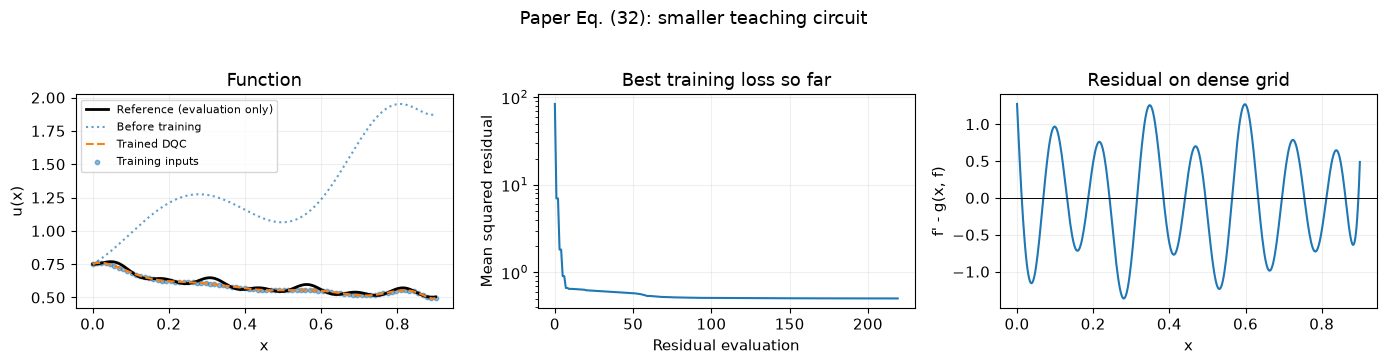

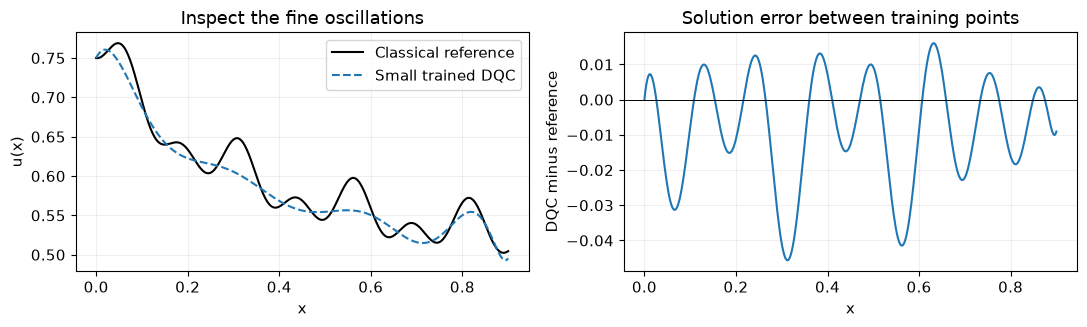

In [10]:
def paper_rhs(x, u):
    return 4*u-6*u**2+np.sin(50*x)+u*np.cos(25*x)-0.5

def paper_rhs_du(x, u):
    return 4-12*u+np.cos(25*x)

paper_model = DQC(nqubits=3, depth=3, kind="ChebT")
paper_x = np.linspace(0, 0.9, 80)
paper_fit = train_ode(paper_model, paper_x, 0.75, paper_rhs, paper_rhs_du,
                      seed=11, max_nfev=220)
reference = solve_ivp(paper_rhs, (0, 0.9), [0.75], method="DOP853",
                      rtol=1e-10, atol=1e-12, dense_output=True)
reference_check = solve_ivp(paper_rhs, (0, 0.9), [0.75], method="DOP853",
                            rtol=1e-12, atol=1e-14, dense_output=True)
assert reference.success and reference_check.success
reference_grid = np.linspace(0, 0.9, 401)
reference_difference = np.max(abs(reference.sol(reference_grid)-reference_check.sol(reference_grid)))
print(f"Reference stability check: {reference_difference:.2e}")
assert reference_difference < 1e-7
paper_metrics = report_fit(paper_model, paper_fit, paper_x, 0.75, paper_rhs,
                          lambda x: reference.sol(x)[0], "Paper Eq. (32): smaller teaching circuit")

# Inspect the learned curve on its own scale: the initial curve above is much larger.
paper_pred, _ = paper_model.predict(paper_fit["params"], paper_model.batch(reference_grid), 0.75)
paper_true = reference.sol(reference_grid)[0]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(reference_grid, paper_true, color="black", label="Classical reference")
ax[0].plot(reference_grid, paper_pred, "--", label="Small trained DQC")
ax[0].set(xlabel="x", ylabel="u(x)", title="Inspect the fine oscillations")
ax[0].legend()
ax[1].plot(reference_grid, paper_pred-paper_true)
ax[1].axhline(0, color="black", lw=0.7)
ax[1].set(xlabel="x", ylabel="DQC minus reference", title="Solution error between training points")
plt.tight_layout(); plt.show()

### Why this can be harder even if the curve looks close

A small-amplitude, high-frequency oscillation can have a large derivative. Consequently, a curve can look close to the reference while its differential residual remains appreciable. Look at both plots and both error metrics.

Try changing `nqubits`, `depth`, `kind`, the seed, or `max_nfev` in the preceding cell. A different result can reflect the available features, optimization difficulty, or both. One run cannot establish which architecture is best. More parameters do not guarantee a better answer under a fixed training budget.

The paper's **evolution-enhanced map** inserts a mixing unitary $e^{-iH\tau}$ after encoding, using an Ising-type Hamiltonian in the example. This changes the functions accessible to a fixed-depth ansatz. It is not itself an ODE time-evolution step. Its benefit also depends on the trainable circuit: an unrestricted ansatz could absorb a fixed unitary, whereas a restricted ansatz may gain useful expressivity.

## 10. Reading the paper's other experiments

### 10.1 Damped oscillations: Eqs. (30)–(31), Fig. 6

The first benchmark is
$$
u'+\lambda u[\kappa+\tan(\lambda x)]=0,\qquad u(0)=u_0.
$$
On intervals where the coefficient is defined, integration gives
$$
u(x)=u_0 e^{-\lambda\kappa x}\cos(\lambda x).
$$
**Reading correction:** Eq. (31) prints an additive constant. For the homogeneous equation (30), the arbitrary integration constant is **multiplicative**. Substitution verifies the formula above. Also, this is a *linear* ODE in $u$, although its solution oscillates and its coefficient depends nonlinearly on $x$.

The coefficient $\tan(\lambda x)$ has poles. Multiplying through by $\cos(\lambda x)$ gives the smooth residual
$$
\cos(\lambda x)u'+\lambda[\kappa\cos(\lambda x)+\sin(\lambda x)]u.
$$
This agrees with the original equation away from poles, but changes residual weighting and does not make the original coefficient defined at a pole. We use it only for the formula check below; we are not silently substituting a different training objective.

Fig. 6 compares Prod, Cheb, and ChebT and varies ansatz depth. The reported results support the importance of feature expressivity for these examples, rather than a general ranking for every ODE.

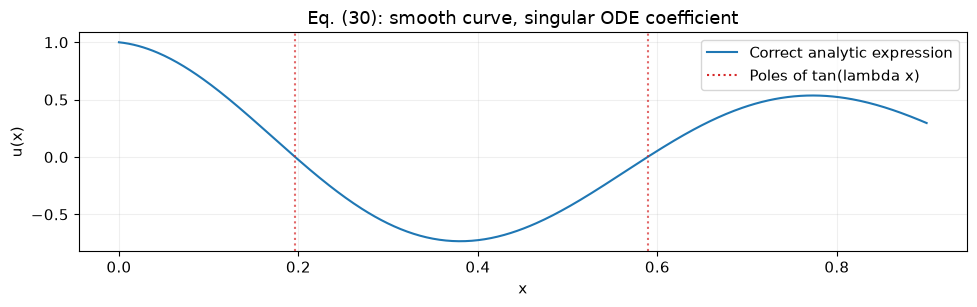

In [11]:
lam, kappa, u0 = 8.0, 0.1, 1.0
xx = np.linspace(0, 0.9, 500)
u = u0*np.exp(-lam*kappa*xx)*np.cos(lam*xx)
du = u0*np.exp(-lam*kappa*xx)*(-lam*kappa*np.cos(lam*xx)-lam*np.sin(lam*xx))
smooth_residual = np.cos(lam*xx)*du + lam*(kappa*np.cos(lam*xx)+np.sin(lam*xx))*u
assert np.max(abs(smooth_residual)) < 1e-12
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(xx, u, label="Correct analytic expression")
for k in range(10):
    pole = (np.pi/2+k*np.pi)/lam
    if pole <= xx.max():
        ax.axvline(pole, color="tab:red", ls=":", alpha=0.7)
ax.plot([], [], color="tab:red", ls=":", label="Poles of tan(lambda x)")
ax.set(xlabel="x", ylabel="u(x)", title="Eq. (30): smooth curve, singular ODE coefficient")
ax.legend(); plt.tight_layout(); plt.show()

### 10.2 Coupled functions: Eqs. (33)–(36), Fig. 8

The paper also solves
$$
u'_1=\lambda_1u_2+\lambda_2u_1,\qquad
u'_2=-\lambda_2u_2-\lambda_1u_1,
$$
using $\lambda_1=5$, $\lambda_2=3$, and $(u_1(0),u_2(0))=(0.5,0)$.

Use two independent circuit models, apply a floating boundary to each, and minimize
$$
\mathcal L=\mathrm{mean}\left[(f'_1-5f_2-3f_1)^2+(f'_2+3f_2+5f_1)^2\right].
$$
Separate circuits still train **jointly**, because each equation depends on both outputs. An alternative is a shared circuit with different readout observables (Sec. III G), which saves resources but couples the representable functions.

The next cell shows the reference and checks the residual assembly. It does **not** train the two-circuit system. It is a blueprint for extending `train_ode` to a vector-valued residual.

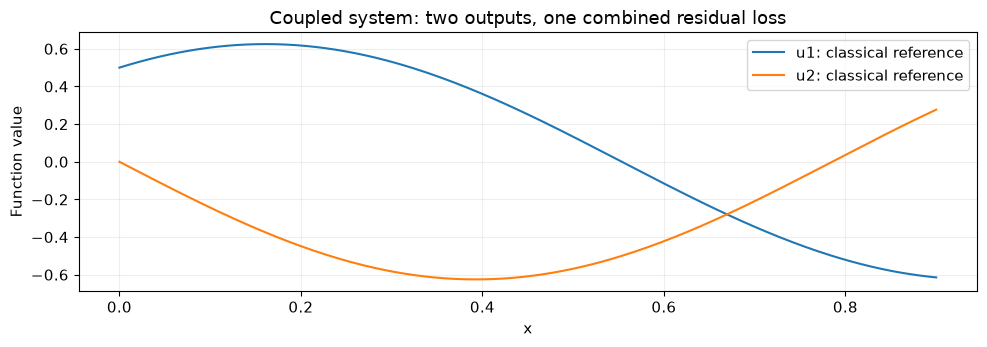

In [12]:
A = np.array([[3., 5.], [-5., -3.]])
initial_pair = np.array([0.5, 0.0])
xc = np.linspace(0, 0.9, 250)
pair = np.stack([expm(A*t) @ initial_pair for t in xc])
dpair = pair @ A.T

def coupled_residual(f1, f2, df1, df2):
    return np.column_stack([df1-5*f2-3*f1, df2+3*f2+5*f1])

assert np.max(abs(coupled_residual(pair[:, 0], pair[:, 1], dpair[:, 0], dpair[:, 1]))) < 1e-12
plt.plot(xc, pair[:, 0], label="u1: classical reference")
plt.plot(xc, pair[:, 1], label="u2: classical reference")
plt.xlabel("x"); plt.ylabel("Function value")
plt.title("Coupled system: two outputs, one combined residual loss")
plt.legend(); plt.tight_layout(); plt.show()

### 10.3 Nozzle flow: Eqs. (40)–(50), Figs. 9–10

The application is **quasi-one-dimensional, inviscid, compressible nozzle flow**, with nondimensional density $\rho(x)$, temperature $T(x)$, and velocity $V(x)$. It is a reduced fluid model, not a general three-dimensional turbulent Navier–Stokes solver.

The nozzle area and heat-capacity ratio are
$$
A(x)=1+4.95(2x-1)^2,\qquad \gamma=1.4.
$$
The narrowest point, $x=0.5$, is the **throat**. The paper seeks a steady solution, so time derivatives vanish. Writing $a(x)=d\ln A/dx$, the original steady conservation residuals are
$$
\begin{aligned}
r_\rho&=\rho V'+\rho V a+V\rho',\\
r_T&=VT'+(\gamma-1)T(V'+Va),\\
r_V&=VV'+\gamma^{-1}(T'+T\rho'/\rho).
\end{aligned}
$$
Rearranging to solve explicitly for derivatives gives the paper's Eqs. (48)–(50):
$$
\rho'=\frac{\rho V^2a}{T-V^2},\quad
T'=\frac{TV^2(\gamma-1)a}{T-V^2},\quad
V'=-\frac{TVa}{T-V^2}.
$$
The denominator vanishes at the sonic condition $V^2=T$. That explicit form becomes singular; a regular transonic solution needs compatibility at the throat. This does not imply all classical fluid solvers fail.

**What the authors actually do (pp. 16–17):**

1. Use six-qubit DQCs with Chebyshev encoding, a depth-6 hardware-efficient ansatz, total-magnetization readout, and floating boundaries. The stated inlet values are $\rho(0)=T(0)=1$, $V(0)=0.1$.
2. Train first on 20 points in the upstream region $(0,0.4)$ for 200 Adam iterations.
3. Continue on 40 points split between $(0,0.4)$ and $(0.6,0.9)$, leaving out the throat region.
4. Add guidance from the upstream solution and five downstream points biased toward the desired supersonic branch; fade that regularization out around iteration 150 of the second, 600-iteration stage.

The omitted throat region and the branch-guiding information are important parts of the experiment. The plotted curve through the omitted interval comes from the global function representation; it is not direct residual enforcement there.

The next cell visualizes the geometry and training regions and implements the undivided steady residuals for inspection. **It does not train or claim to reproduce the nozzle profiles.** Changing from divided to undivided residuals changes optimization weighting, even where the equations have the same roots.

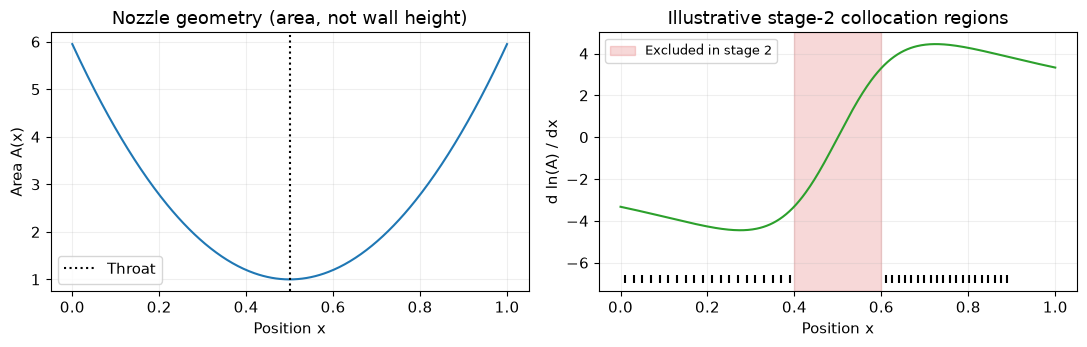

Steady residual algebra checked away from the sonic condition.


In [13]:
def nozzle_area(x):
    return 1+4.95*(2*x-1)**2

def nozzle_log_area_prime(x):
    return 19.8*(2*x-1)/nozzle_area(x)

def nozzle_steady_residual(x, values, derivatives, gamma=1.4):
    # Columns are density, temperature, velocity. Requires positive density.
    rho, temperature, velocity = values.T
    drho, dtemperature, dvelocity = derivatives.T
    if np.any(rho <= 0):
        raise ValueError("Density must be positive for this residual form.")
    a = nozzle_log_area_prime(np.asarray(x))
    return np.column_stack([
        rho*dvelocity + rho*velocity*a + velocity*drho,
        velocity*dtemperature + (gamma-1)*temperature*(dvelocity+velocity*a),
        velocity*dvelocity + (dtemperature+temperature*drho/rho)/gamma])

xn = np.linspace(0, 1, 400)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(xn, nozzle_area(xn), color="tab:blue")
ax[0].axvline(0.5, color="black", ls=":", label="Throat")
ax[0].set(xlabel="Position x", ylabel="Area A(x)", title="Nozzle geometry (area, not wall height)")
ax[0].legend()
ax[1].plot(xn, nozzle_log_area_prime(xn), color="tab:green")
ax[1].axvspan(0.4, 0.6, alpha=0.18, color="tab:red", label="Excluded in stage 2")
for region in [np.linspace(0.01, 0.39, 20), np.linspace(0.61, 0.89, 20)]:
    ax[1].scatter(region, np.full_like(region, -6.8), marker="|", color="black")
ax[1].set(xlabel="Position x", ylabel="d ln(A) / dx", title="Illustrative stage-2 collocation regions")
ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

# Verify algebraic equivalence away from the sonic denominator.
xt = np.array([0.1, 0.25, 0.75])
vals = np.array([[1., 1., 0.1], [0.95, 0.98, 0.2], [0.5, 0.7, 1.1]])
rho, temp, vel = vals.T
a = nozzle_log_area_prime(xt)
denom = temp-vel**2
derivs = np.column_stack([rho*vel**2*a/denom,
                         temp*vel**2*0.4*a/denom, -temp*vel*a/denom])
assert np.max(abs(nozzle_steady_residual(xt, vals, derivs))) < 1e-12
print("Steady residual algebra checked away from the sonic condition.")

## 11. Exact differentiation does not remove measurement noise

The shift identity eliminates **finite-difference truncation error**. It does not remove finite-shot uncertainty, device noise, floating-point error, imperfect optimization, or limited expressivity.

For a $Z$ measurement with mean $q$, an estimate using $S$ shots has variance $(1-q^2)/S$. For independent shifted estimates of $\cos\alpha$,
$$
\widehat{q'}=\frac{\hat q_+-\hat q_-}{2},\qquad
\mathrm{Var}(\widehat{q'})=\frac{(1-q_+^2)+(1-q_-^2)}{4S}.
$$
For an $x$ derivative, angle-chain factors such as $\varphi'(x)$ multiply the uncertainty. Near encoding endpoints, those factors can be large. Squaring a noisy residual also changes the expectation of the observed loss: $\mathbb E[\hat r^2]=r^2+\mathrm{Var}(\hat r)$ for an unbiased residual estimator.

Below, each replicate estimates the one-qubit derivative from fresh binomial samples. This is a **measurement-only illustration**, not a noise study of the trained models or a simulation of hardware gate errors. The paper states in Sec. V that it did not study noise effects on algorithm performance.

  100 shots per shifted circuit: mean=-0.71750, std=0.04946; exact=-0.71736
 1000 shots per shifted circuit: mean=-0.71779, std=0.01542; exact=-0.71736
10000 shots per shifted circuit: mean=-0.71751, std=0.00515; exact=-0.71736


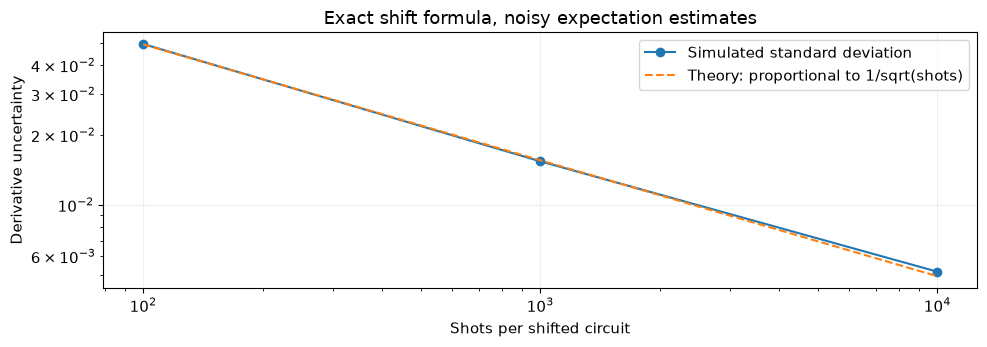

In [14]:
rng = np.random.default_rng(42)
angle = 0.8
shots = np.array([100, 1000, 10000])
replicates = 2000
measured_std, theoretical_std = [], []
qplus, qminus = np.cos(angle+np.pi/2), np.cos(angle-np.pi/2)
for S in shots:
    plus = 2*rng.binomial(S, (1+qplus)/2, size=replicates)/S-1
    minus = 2*rng.binomial(S, (1+qminus)/2, size=replicates)/S-1
    estimates = (plus-minus)/2
    measured_std.append(np.std(estimates, ddof=1))
    theoretical_std.append(np.sqrt(((1-qplus*qplus)+(1-qminus*qminus))/(4*S)))
    print(f"{S:5d} shots per shifted circuit: mean={estimates.mean(): .5f}, "
          f"std={estimates.std(ddof=1):.5f}; exact={-np.sin(angle):.5f}")
plt.loglog(shots, measured_std, "o-", label="Simulated standard deviation")
plt.loglog(shots, theoretical_std, "--", label="Theory: proportional to 1/sqrt(shots)")
plt.xlabel("Shots per shifted circuit"); plt.ylabel("Derivative uncertainty")
plt.title("Exact shift formula, noisy expectation estimates")
plt.legend(); plt.tight_layout(); plt.show()

## 12. What is gained, and what remains difficult?

**What the method offers:** a continuous circuit-defined trial function; analytic circuit derivatives; classical handling of nonlinear terms; and a way to train against differential equations and initial conditions without a full labeled solution dataset. Once trained, evaluate a new input by running the learned circuit at that input.

**What this paper does not establish:** an end-to-end quantum speedup over strong classical solvers, guaranteed convergence, general hardware noise robustness, or a solution to unrestricted fluid dynamics. A large Hilbert space alone is not a runtime comparison. Our NumPy simulation explicitly uses memory proportional to $2^N$ and is a classical computation.

For one readout setting, $M$ inputs, $N$ input-dependent gates, and $P$ trainable gate angles:

- Function plus first input derivative takes roughly $M(1+2N)$ circuit settings before reuse and batching.
- A direct shifted construction of parameter derivatives can require on the order of $2PM(1+2N)$ settings, plus boundary evaluations and any additional observables.
- Each setting needs repeated shots on hardware. Noncommuting readouts may need separate measurement settings. Our $Z_j$ observables commute and can be read together.

This is bookkeeping for the straightforward implementation, not an optimized lower bound. Our implementation evaluates some reusable values more than once for clarity. Large gradients, noise, nonconvex losses, flat regions of the loss landscape, and collocation coverage can all affect training.

| Paper element | Notebook implementation | Difference to remember |
|---|---|---|
| Expectation-valued trial function | Exact statevector readout | No hardware sampling in training |
| ChebT feature map | Same $2j\arccos x$ angles | Smaller register |
| Hardware-efficient ansatz | $R_y$–$R_z$ plus CNOT layers | Different gate pattern and depth |
| Differential and parameter derivatives | Parameter shifts plus chain rule | Independent finite differences used only as checks |
| Floating boundary | Recomputed $u_0-q(0)$ | Exact only in this noiseless setting |
| Optimizer | Analytic-Jacobian least squares | Paper uses Adam |
| Eq. (32) experiment | Smaller circuit on the same equation | No evolution-enhanced second stage |
| Coupled and nozzle applications | Equations, diagnostics, and plots | No full DQC training reproduction |

## 13. Experiments to make the ideas stick

Run one change at a time and compare the dense-grid metrics, not just the training loss.

1. **Change the boundary.** In Experiment A, change `u0` from 1 to 0.5 and the reporting reference to `lambda x: 0.5/(1+0.5*x)`. Why does the initial-condition error remain tiny?
2. **Reduce the training grid.** Use 5 points instead of 31. Does low training loss still imply low dense-grid residual?
3. **Change the feature map.** Replace `ChebT` with `Prod` or `Cheb` and rerun. Repeat several seeds before drawing conclusions.
4. **Change the circuit size.** Increase depth or qubit count. Record runtime, residual MSE, and solution RMSE. Does more capacity always help within the same budget?
5. **Test an incorrect derivative.** In a copy, remove `batch.dphi` from `observables`. Which validation assertion catches the missing chain rule?
6. **Extend to a system.** Use two DQC instances, concatenate their parameters, and stack the two residual columns from `coupled_residual`. Include cross-output terms in the Jacobian.

<details>
<summary><b>Concept checks and answers</b></summary>

**Where is the solution stored?** In the chosen circuit structure and learned quantum angles/classical readout weights. Its value at a requested input is an expectation value after boundary processing.

**Is the circuit a physical simulation of the differential equation's dynamics?** Not here. It is a trainable function approximator; the equation enters the classical residual.

**Why is the method able to handle nonlinear equations?** The classical loss can multiply and otherwise combine measured function values, such as $f^2$ or $\rho V'$. The underlying quantum gates remain linear.

**Why not differentiate with tiny input steps?** Shift identities compute derivatives of these circuits analytically, avoiding truncation error and small-step cancellation. Independent finite differences are still useful as implementation checks.

**Does a zero residual determine the desired solution?** Only together with appropriate initial/boundary conditions and any needed uniqueness assumptions. Zero on finitely many sampled inputs is weaker than zero throughout the domain.

**Is $L_Q$ a training loss?** In these examples it is an evaluation metric against a known reference. Our training functions never receive that reference.

**Does “analytic derivative” mean “exact ODE solution”?** No. It means the derivative of the current trial circuit is analytically represented. The trial function may still be inaccurate.

</details>

## 14. Reading guide and source

Primary source: **the supplied local PDF**, [2011.10395v2.pdf](2011.10395v2.pdf).  
Online record: [arXiv:2011.10395v2](https://arxiv.org/abs/2011.10395v2).  
Published article: [Physical Review A 103, 052416](https://doi.org/10.1103/PhysRevA.103.052416).

| If you want to revisit… | Read… |
|---|---|
| The entire algorithm at a glance | Fig. 1; Sec. II; Sec. III H |
| Circuit outputs and shifted derivatives | Fig. 2–3; Eqs. (1)–(10) |
| Chebyshev encodings | Sec. III A; Eqs. (11)–(15) |
| Trainable architecture and readout | Sec. III B–C; Fig. 5; Eq. (18) |
| Residual loss and initial conditions | Sec. III D–E; Eqs. (19)–(27) |
| Guidance from prior values and multiple outputs | Sec. III F–G; Eqs. (28)–(29) |
| Oscillatory and nonlinear scalar benchmarks | Sec. IV; Eqs. (30)–(32); Figs. 6–7 |
| Coupled equations and boundary comparisons | Eqs. (33)–(36); Fig. 8 |
| Nozzle-flow setup and staged training | Eqs. (40)–(50); Figs. 9–10; pp. 15–17 |
| Noise, trainability, and possible advantage | Sec. V |

All plots in this notebook are generated by the cells. They are teaching illustrations or explicitly labeled computations, not copied experimental results. The formula corrections are justified by direct substitution and numerical checks in the notebook.

You should now be able to trace the full mechanism: **input → feature rotations → trainable circuit → measured function and shifted derivatives → differential-equation residual → classical parameter update**.